# Garbage Classification — Сравнение трёх моделей
**Модели:** Custom CNN | EfficientNet-B0 | ResNet50

---
## 1. Импорты

In [1]:
import os
import copy
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.metrics import confusion_matrix, classification_report

import kagglehub

print('Все библиотеки импортированы')

Все библиотеки импортированы


c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## 2. Устройство и seed

In [6]:
SEED = 10

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', device)

DEVICE: cpu


---
## 3. Загрузка датасета

In [4]:
path = kagglehub.dataset_download('asdasdasasdas/garbage-classification')

data_root = os.path.join(
    path,
    'Garbage classification',
    'Garbage classification'
)

full_dataset = datasets.ImageFolder(root=data_root)
classes = full_dataset.classes
num_classes = len(classes)

print('DATA ROOT:', data_root)
print(f'КЛАССЫ ({num_classes}):', classes)
print(f'ВСЕГО ИЗОБРАЖЕНИЙ: {len(full_dataset)}')

DATA ROOT: C:\Users\Иван\.cache\kagglehub\datasets\asdasdasasdas\garbage-classification\versions\2\Garbage classification\Garbage classification
КЛАССЫ (6): ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
ВСЕГО ИЗОБРАЖЕНИЙ: 2527


---
## 4. Трансформы

In [2]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print('Трансформы созданы')

Трансформы созданы


---
## 5. Сплит и DataLoader'ы

In [7]:
train_size = 1593
val_size = 176
test_size = len(full_dataset) - train_size - val_size

generator = torch.Generator().manual_seed(SEED)

train_indices, val_indices, test_indices = random_split(
    range(len(full_dataset)),
    [train_size, val_size, test_size],
    generator=generator
)

def make_subset(root, transform, indices):
    ds = datasets.ImageFolder(root=root, transform=transform)
    ds.samples = [ds.samples[i] for i in indices.indices]
    return ds

train_dataset = make_subset(data_root, train_transform,    train_indices)
val_dataset = make_subset(data_root, val_test_transform, val_indices)
test_dataset = make_subset(data_root, val_test_transform, test_indices)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train: {train_size} | Val: {val_size} | Test: {test_size}')
print('DataLoader\'ы созданы')

Train: 1593 | Val: 176 | Test: 758
DataLoader'ы созданы


---
## 6. Общие функции (train / evaluate / early stopping)

In [8]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)


def train_epoch(model, loader, optimizer):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    return running_loss / len(loader), 100 * correct / total


def evaluate(model, loader, return_preds=False):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            if return_preds:
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

    loss_avg = running_loss / len(loader)
    acc = 100 * correct / total

    if return_preds:
        return loss_avg, acc, all_preds, all_labels
    return loss_avg, acc


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.05):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_acc = 0

    def step(self, val_acc):
        if val_acc > self.best_acc + self.min_delta:
            self.best_acc = val_acc
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience


def run_training(model, optimizer, scheduler, epochs, name, start_es_from=0):
    """Универсальный цикл обучения. Возвращает историю и лучшие веса."""
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc':  [], 'val_acc':  [],
        'lr':         []
    }
    best_val_acc = 0
    best_model_weights = copy.deepcopy(model.state_dict())
    early_stopping = EarlyStopping(patience=5)

    print(f'\n{'='*55}')
    print(f'  Обучение: {name}')
    print(f'{'='*55}')

    for epoch in range(epochs):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)

        if scheduler is not None:
            scheduler.step()

        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['lr'].append(current_lr)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_weights = copy.deepcopy(model.state_dict())

        print(f'  Epoch [{epoch+1:>2}/{epochs}] | LR: {current_lr:.2e} | '
              f'Train: {train_acc:.2f}% | Val: {val_acc:.2f}% | Best: {best_val_acc:.2f}%')

        if epoch >= start_es_from and early_stopping.step(val_acc):
            print(f'\n  Early stopping на эпохе {epoch+1}')
            break

    model.load_state_dict(best_model_weights)
    return history


def denorm(img_tensor):
    img = img_tensor.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    return np.clip(img * std + mean, 0, 1)


print('Общие функции готовы')

Общие функции готовы


---
# МОДЕЛЬ 1. CNN

### 7. Определение CNN

In [9]:
class GarbageCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.4),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

cnn_model = GarbageCNN().to(device)
print('CNN создана')
print(f'Параметров: {sum(p.numel() for p in cnn_model.parameters()):,}')

CNN создана
Параметров: 616,806


### 8. Обучение CNN

In [ ]:
cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(), lr=3e-4, weight_decay=1e-4
)

cnn_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    cnn_optimizer, T_max=40, eta_min=1e-6
)

cnn_history = run_training(
    model = cnn_model,
    optimizer = cnn_optimizer,
    scheduler = cnn_scheduler,
    epochs = 40,
    name = 'CNN'
)


  Обучение: CNN


c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  Epoch [ 1/40] | LR: 3.00e-04 | Train: 35.34% | Val: 46.02% | Best: 46.02%
  Epoch [ 2/40] | LR: 2.98e-04 | Train: 45.83% | Val: 55.68% | Best: 55.68%
  Epoch [ 3/40] | LR: 2.96e-04 | Train: 51.22% | Val: 53.98% | Best: 55.68%
  Epoch [ 4/40] | LR: 2.93e-04 | Train: 53.80% | Val: 54.55% | Best: 55.68%
  Epoch [ 5/40] | LR: 2.89e-04 | Train: 54.80% | Val: 52.84% | Best: 55.68%
  Epoch [ 6/40] | LR: 2.84e-04 | Train: 55.81% | Val: 59.09% | Best: 59.09%
  Epoch [ 7/40] | LR: 2.78e-04 | Train: 55.05% | Val: 55.68% | Best: 59.09%
  Epoch [ 8/40] | LR: 2.71e-04 | Train: 57.56% | Val: 63.07% | Best: 63.07%
  Epoch [ 9/40] | LR: 2.64e-04 | Train: 56.50% | Val: 54.55% | Best: 63.07%
  Epoch [10/40] | LR: 2.56e-04 | Train: 59.57% | Val: 54.55% | Best: 63.07%
  Epoch [11/40] | LR: 2.48e-04 | Train: 61.02% | Val: 60.80% | Best: 63.07%
  Epoch [12/40] | LR: 2.38e-04 | Train: 61.08% | Val: 46.02% | Best: 63.07%
  Epoch [13/40] | LR: 2.29e-04 | Train: 62.96% | Val: 63.07% | Best: 63.07%

  ⏹ Early s

### 9. Тест CNN

In [17]:
cnn_test_loss, cnn_test_acc, cnn_preds, cnn_labels = evaluate(
    cnn_model, test_loader, return_preds=True
)

print(f'\n CNN — Test Accuracy: {cnn_test_acc:.2f}%')
print('\nClassification Report:')
print(classification_report(cnn_labels, cnn_preds, target_names=classes))


 CNN — Test Accuracy: 62.53%

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.80      0.79      0.79       117
       glass       0.44      0.86      0.58       156
       metal       0.89      0.31      0.46       134
       paper       0.75      0.73      0.74       172
     plastic       0.66      0.57      0.61       143
       trash       0.00      0.00      0.00        36

    accuracy                           0.63       758
   macro avg       0.59      0.54      0.53       758
weighted avg       0.67      0.63      0.61       758



c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

---
# МОДЕЛЬ 2. EfficientNet-B0

### 10. Определение EfficientNet-B0

In [10]:
eff_backbone = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)

eff_backbone.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(256, num_classes)
)

for param in eff_backbone.features.parameters():
    param.requires_grad = False

eff_model = eff_backbone.to(device)

active = sum(p.numel() for p in eff_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in eff_model.parameters())
print(f'EfficientNet-B0 создан')
print(f'Всего параметров: {total:,}')
print(f'Обучаемых (фаза 1): {active:,}')

EfficientNet-B0 создан
Всего параметров: 4,337,026
Обучаемых (фаза 1): 329,478


### 11. Обучение EfficientNet-B0 (фаза 1: только голова)

In [ ]:
FROZEN_EPOCHS = 5

eff_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, eff_model.parameters()),
    lr=3e-4, weight_decay=1e-4
)

eff_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    eff_optimizer, T_max=FROZEN_EPOCHS, eta_min=1e-6
)

eff_history = run_training(
    model = eff_model,
    optimizer = eff_optimizer,
    scheduler = eff_scheduler,
    epochs = FROZEN_EPOCHS,
    name = 'EfficientNet-B0 — Фаза 1 (backbone заморожен)',
    start_es_from = FROZEN_EPOCHS
)


  Обучение: EfficientNet-B0 — Фаза 1 (backbone заморожен)


c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  Epoch [ 1/5] | LR: 2.71e-04 | Train: 50.85% | Val: 75.57% | Best: 75.57%
  Epoch [ 2/5] | LR: 1.97e-04 | Train: 69.81% | Val: 75.00% | Best: 75.57%
  Epoch [ 3/5] | LR: 1.04e-04 | Train: 73.89% | Val: 76.70% | Best: 76.70%
  Epoch [ 4/5] | LR: 2.96e-05 | Train: 75.58% | Val: 76.70% | Best: 76.70%
  Epoch [ 5/5] | LR: 1.00e-06 | Train: 73.82% | Val: 76.70% | Best: 76.70%


### 12. Обучение EfficientNet-B0 (фаза 2: fine-tune всей сети)

In [ ]:
for param in eff_model.features.parameters():
    param.requires_grad = True

active = sum(p.numel() for p in eff_model.parameters() if p.requires_grad)
print(f'Backbone разморожен | Обучаемых параметров: {active:,}')

eff_optimizer2 = torch.optim.AdamW([
    {'params': eff_model.features.parameters(), 'lr': 1e-5},
    {'params': eff_model.classifier.parameters(), 'lr': 1e-4},
], weight_decay=1e-4)

eff_scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    eff_optimizer2, T_max=25, eta_min=1e-7
)

eff_history2 = run_training(
    model = eff_model,
    optimizer = eff_optimizer2,
    scheduler = eff_scheduler2,
    epochs = 25,
    name = 'EfficientNet-B0 — Фаза 2 (fine-tune)'
)

for key in eff_history:
    eff_history[key] = eff_history[key] + eff_history2[key]

eff_frozen_epochs = FROZEN_EPOCHS 

🔓 Backbone разморожен | Обучаемых параметров: 4,337,026

  Обучение: EfficientNet-B0 — Фаза 2 (fine-tune)
  Epoch [ 1/25] | LR: 9.96e-06 | Train: 73.26% | Val: 77.27% | Best: 77.27%
  Epoch [ 2/25] | LR: 9.84e-06 | Train: 77.09% | Val: 77.27% | Best: 77.27%
  Epoch [ 3/25] | LR: 9.65e-06 | Train: 78.53% | Val: 80.68% | Best: 80.68%
  Epoch [ 4/25] | LR: 9.39e-06 | Train: 81.67% | Val: 79.55% | Best: 80.68%
  Epoch [ 5/25] | LR: 9.05e-06 | Train: 82.42% | Val: 80.11% | Best: 80.68%
  Epoch [ 6/25] | LR: 8.66e-06 | Train: 82.42% | Val: 78.98% | Best: 80.68%
  Epoch [ 7/25] | LR: 8.21e-06 | Train: 83.74% | Val: 81.25% | Best: 81.25%
  Epoch [ 8/25] | LR: 7.70e-06 | Train: 85.56% | Val: 82.39% | Best: 82.39%
  Epoch [ 9/25] | LR: 7.16e-06 | Train: 85.19% | Val: 82.39% | Best: 82.39%
  Epoch [10/25] | LR: 6.58e-06 | Train: 87.32% | Val: 81.25% | Best: 82.39%
  Epoch [11/25] | LR: 5.98e-06 | Train: 88.32% | Val: 82.95% | Best: 82.95%
  Epoch [12/25] | LR: 5.36e-06 | Train: 88.20% | Val: 82.9

### 13. Тест EfficientNet-B0

In [21]:
eff_test_loss, eff_test_acc, eff_preds, eff_labels = evaluate(
    eff_model, test_loader, return_preds=True
)

print(f'\nEfficientNet-B0 — Test Accuracy: {eff_test_acc:.2f}%')
print('\nClassification Report:')
print(classification_report(eff_labels, eff_preds, target_names=classes))


EfficientNet-B0 — Test Accuracy: 87.47%

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.96      0.89      0.92       117
       glass       0.87      0.88      0.88       156
       metal       0.86      0.88      0.87       134
       paper       0.88      0.90      0.89       172
     plastic       0.87      0.87      0.87       143
       trash       0.69      0.69      0.69        36

    accuracy                           0.87       758
   macro avg       0.86      0.85      0.85       758
weighted avg       0.88      0.87      0.87       758



---
# МОДЕЛЬ 3. ResNet50

### 14. Определение ResNet50

In [11]:
res_backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

res_backbone.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, num_classes)
)

res_model = res_backbone.to(device)

total  = sum(p.numel() for p in res_model.parameters())
print(f'ResNet50 создан')
print(f'Всего параметров: {total:,}')

ResNet50 создан
Всего параметров: 24,560,198


### 15. Обучение ResNet50

In [ ]:
res_optimizer = torch.optim.AdamW([
    {'params': res_model.layer1.parameters(), 'lr': 5.5e-5},
    {'params': res_model.layer2.parameters(), 'lr': 5.5e-5},
    {'params': res_model.layer3.parameters(), 'lr': 5.5e-5},
    {'params': res_model.layer4.parameters(), 'lr': 5.5e-5},
    {'params': res_model.fc.parameters(),     'lr': 5.5e-4},
], weight_decay=1e-4)

res_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    res_optimizer, T_max=15, eta_min=1e-7
)

res_history = run_training(
    model = res_model,
    optimizer = res_optimizer,
    scheduler = res_scheduler,
    epochs = 8,
    name = 'ResNet50'
)


  Обучение: ResNet50


c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  Epoch [ 1/8] | LR: 5.44e-05 | Train: 65.91% | Val: 83.52% | Best: 83.52%
  Epoch [ 2/8] | LR: 5.26e-05 | Train: 87.70% | Val: 87.50% | Best: 87.50%
  Epoch [ 3/8] | LR: 4.98e-05 | Train: 93.97% | Val: 88.64% | Best: 88.64%
  Epoch [ 4/8] | LR: 4.59e-05 | Train: 96.92% | Val: 89.77% | Best: 89.77%
  Epoch [ 5/8] | LR: 4.13e-05 | Train: 97.61% | Val: 93.18% | Best: 93.18%
  Epoch [ 6/8] | LR: 3.60e-05 | Train: 98.81% | Val: 92.05% | Best: 93.18%
  Epoch [ 7/8] | LR: 3.04e-05 | Train: 98.81% | Val: 90.91% | Best: 93.18%
  Epoch [ 8/8] | LR: 2.47e-05 | Train: 99.37% | Val: 91.48% | Best: 93.18%


### 16. Тест ResNet50

In [24]:
res_test_loss, res_test_acc, res_preds, res_labels = evaluate(
    res_model, test_loader, return_preds=True
)

print(f'\nResNet50 — Test Accuracy: {res_test_acc:.2f}%')
print('\nClassification Report:')
print(classification_report(res_labels, res_preds, target_names=classes))


ResNet50 — Test Accuracy: 91.82%

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.98      0.94      0.96       117
       glass       0.88      0.96      0.92       156
       metal       0.91      0.96      0.93       134
       paper       0.95      0.93      0.94       172
     plastic       0.94      0.82      0.87       143
       trash       0.78      0.86      0.82        36

    accuracy                           0.92       758
   macro avg       0.90      0.91      0.91       758
weighted avg       0.92      0.92      0.92       758



---
# СРАВНЕНИЕ МОДЕЛЕЙ

### 17. Графики обучения каждой модели

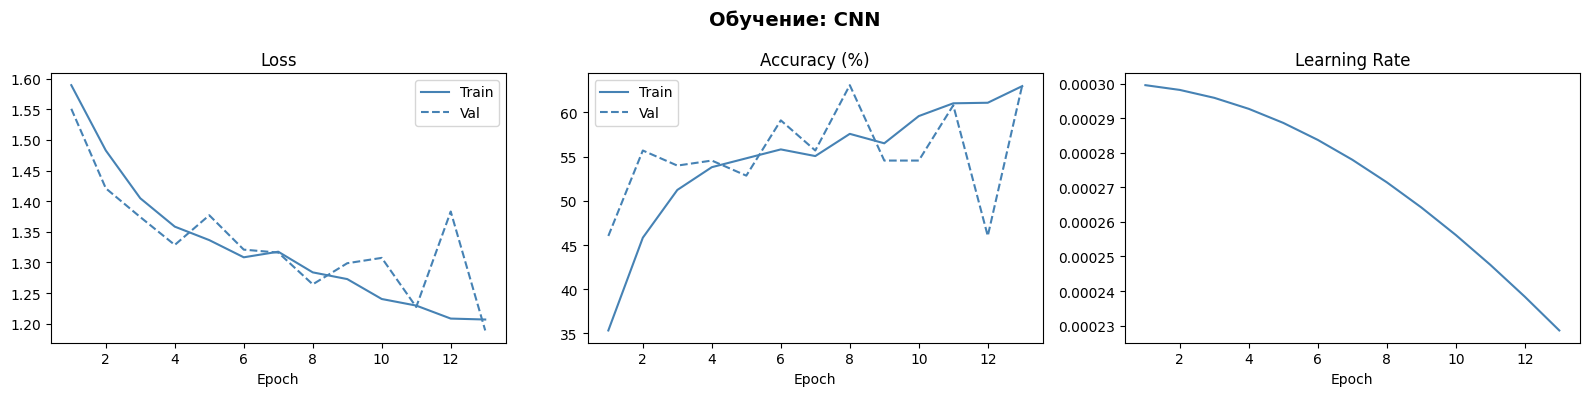

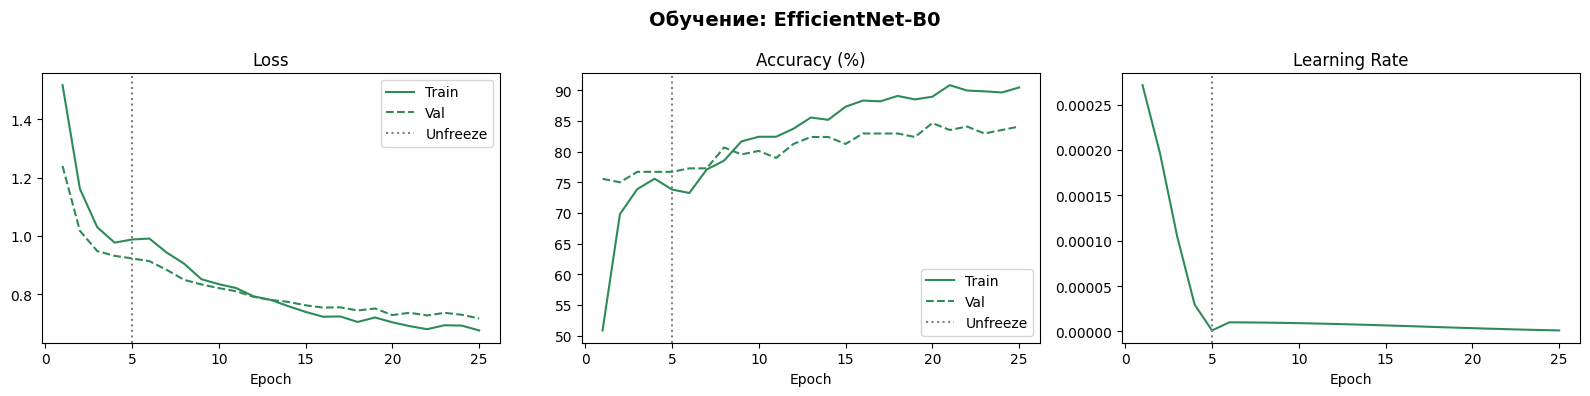

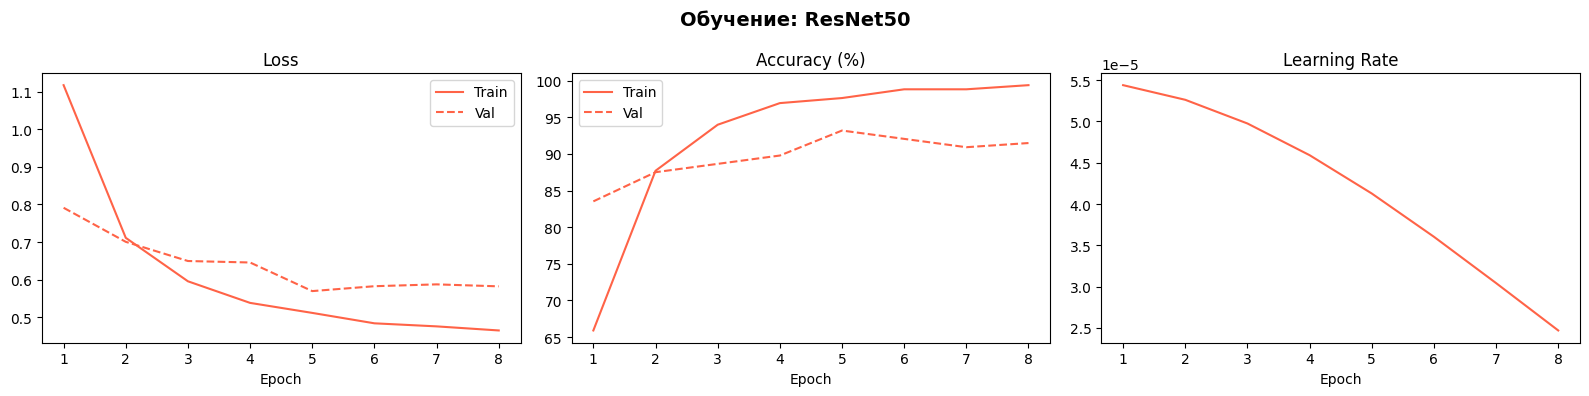

In [ ]:
def plot_training(history, name, color, frozen_at=None):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f'Обучение: {name}', fontsize=14, fontweight='bold')

    epochs = range(1, len(history['train_loss']) + 1)

    axes[0].plot(epochs, history['train_loss'], label='Train', color=color)
    axes[0].plot(epochs, history['val_loss'],   label='Val',   color=color, linestyle='--')
    if frozen_at:
        axes[0].axvline(frozen_at, color='gray', linestyle=':', label='Unfreeze')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(epochs, history['train_acc'], label='Train', color=color)
    axes[1].plot(epochs, history['val_acc'],   label='Val',   color=color, linestyle='--')
    if frozen_at:
        axes[1].axvline(frozen_at, color='gray', linestyle=':', label='Unfreeze')
    axes[1].set_title('Accuracy (%)')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()

    axes[2].plot(epochs, history['lr'], color=color)
    if frozen_at:
        axes[2].axvline(frozen_at, color='gray', linestyle=':')
    axes[2].set_title('Learning Rate')
    axes[2].set_xlabel('Epoch')

    plt.tight_layout()
    plt.show()


plot_training(cnn_history, 'CNN', color='steelblue')
plot_training(eff_history, 'EfficientNet-B0', color='seagreen', frozen_at=eff_frozen_epochs)
plot_training(res_history, 'ResNet50', color='tomato')

### 18. Матрицы ошибок

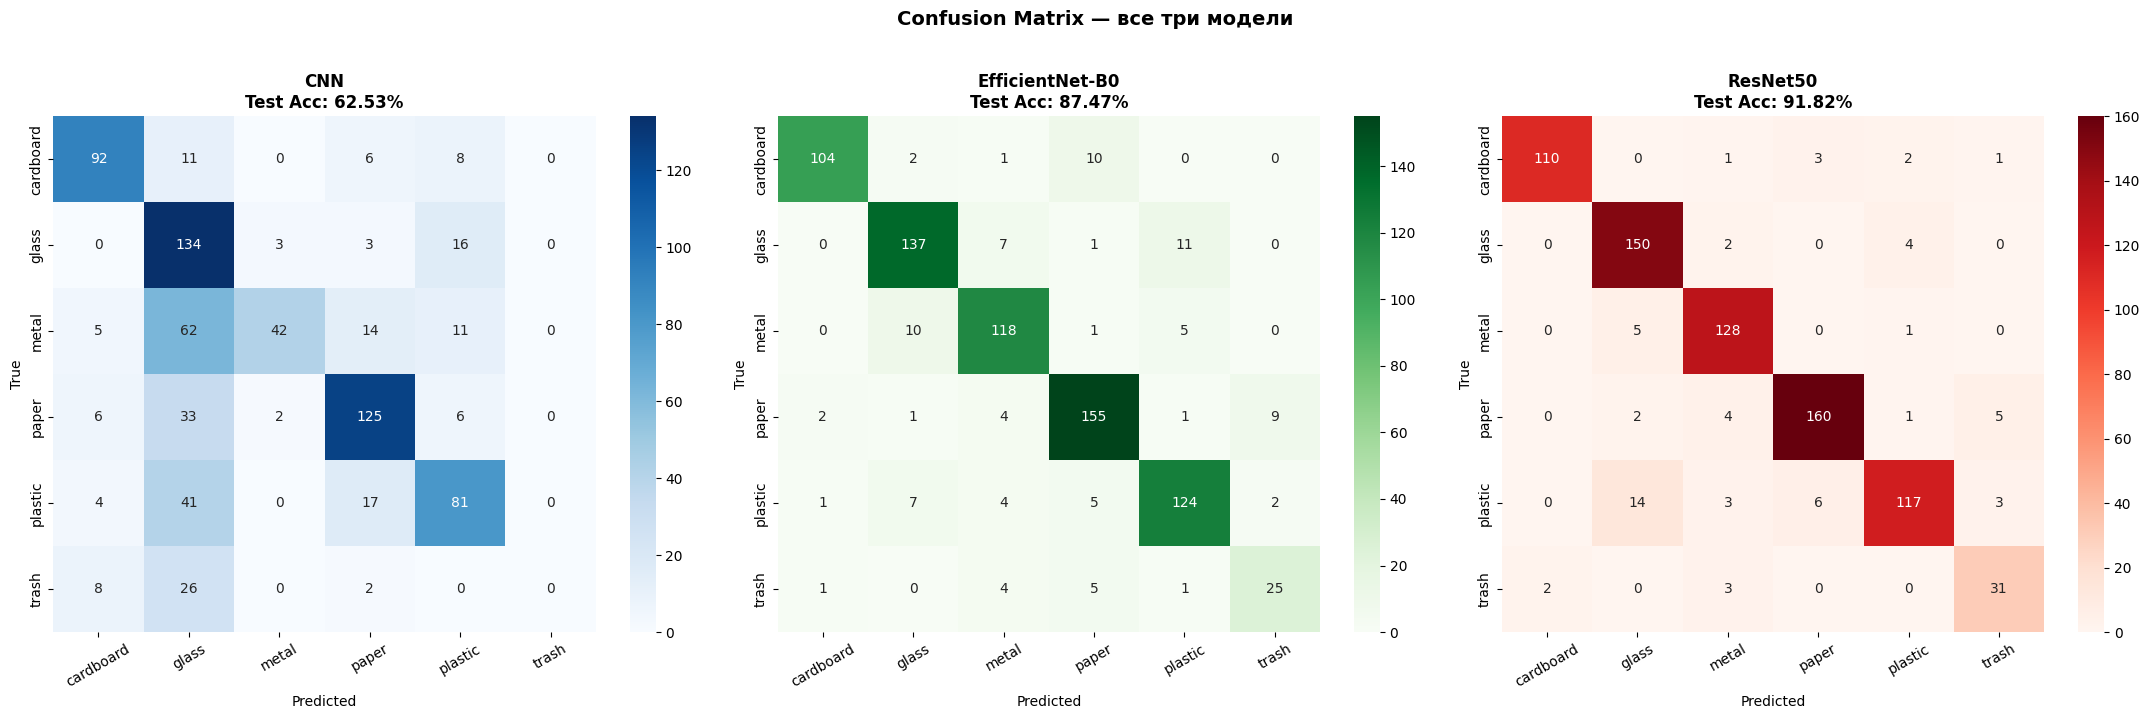

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

models_info = [
    ('CNN', cnn_labels, cnn_preds, cnn_test_acc, 'Blues'),
    ('EfficientNet-B0', eff_labels, eff_preds, eff_test_acc, 'Greens'),
    ('ResNet50', res_labels, res_preds, res_test_acc, 'Reds'),
]

for ax, (name, true, pred, acc, cmap) in zip(axes, models_info):
    cm = confusion_matrix(true, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap=cmap,
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )
    ax.set_title(f'{name}\nTest Acc: {acc:.2f}%', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Confusion Matrix — все три модели', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 19. Примеры удачных и неудачных предсказаний

In [12]:
def get_predictions_sample(model, loader, n=4):
    model.eval()
    correct_imgs, correct_true, correct_pred, correct_conf = [], [], [], []
    wrong_imgs, wrong_true, wrong_pred, wrong_conf = [], [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images_gpu = images.to(device)
            probs = torch.softmax(model(images_gpu), dim=1)
            conf, pred = torch.max(probs, 1)

            for i in range(len(labels)):
                img = denorm(images[i])
                t = labels[i].item()
                p = pred[i].item()
                c = conf[i].item()

                if p == t and len(correct_imgs) < n:
                    correct_imgs.append(img)
                    correct_true.append(classes[t])
                    correct_pred.append(classes[p])
                    correct_conf.append(c)

                if p != t and len(wrong_imgs) < n:
                    wrong_imgs.append(img)
                    wrong_true.append(classes[t])
                    wrong_pred.append(classes[p])
                    wrong_conf.append(c)

            if len(correct_imgs) >= n and len(wrong_imgs) >= n:
                break

    return (correct_imgs, correct_true, correct_pred, correct_conf, wrong_imgs, wrong_true, wrong_pred, wrong_conf)


def plot_predictions(model, name, color, n=4):
    (
        c_imgs, c_true, c_pred, c_conf,
        w_imgs, w_true, w_pred, w_conf
    ) = get_predictions_sample(model, test_loader, n=n)

    fig, axes = plt.subplots(2, n, figsize=(4 * n, 5))
    fig.suptitle(f'{name} — Удачные и Неудачные  предсказания',
                 fontsize=13, fontweight='bold', color=color)

    for i in range(n):
        axes[0, i].imshow(c_imgs[i])
        axes[0, i].set_title(
            f'{c_pred[i]}\n({c_conf[i]*100:.1f}%)',
            color='green', fontsize=9
        )
        axes[0, i].axis('off')

        axes[1, i].imshow(w_imgs[i])
        axes[1, i].set_title(
            f'Pred: {w_pred[i]}\n  True: {w_true[i]} ({w_conf[i]*100:.1f}%)',
            color='red', fontsize=9
        )
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()


plot_predictions(cnn_model, 'CNN', color='steelblue')
plot_predictions(eff_model, 'EfficientNet-B0', color='seagreen')
plot_predictions(res_model, 'ResNet50', color='tomato')

c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


KeyboardInterrupt: 

### 20. Итоговое сравнение моделей


  Модель                 Test Acc   Best Val    Эпох     Параметров
  CNN                      62.53%     63.07%      13        616,806
  EfficientNet-B0          87.47%     84.66%      25      4,337,026
  ResNet50                 91.82%     93.18%       8     24,560,198


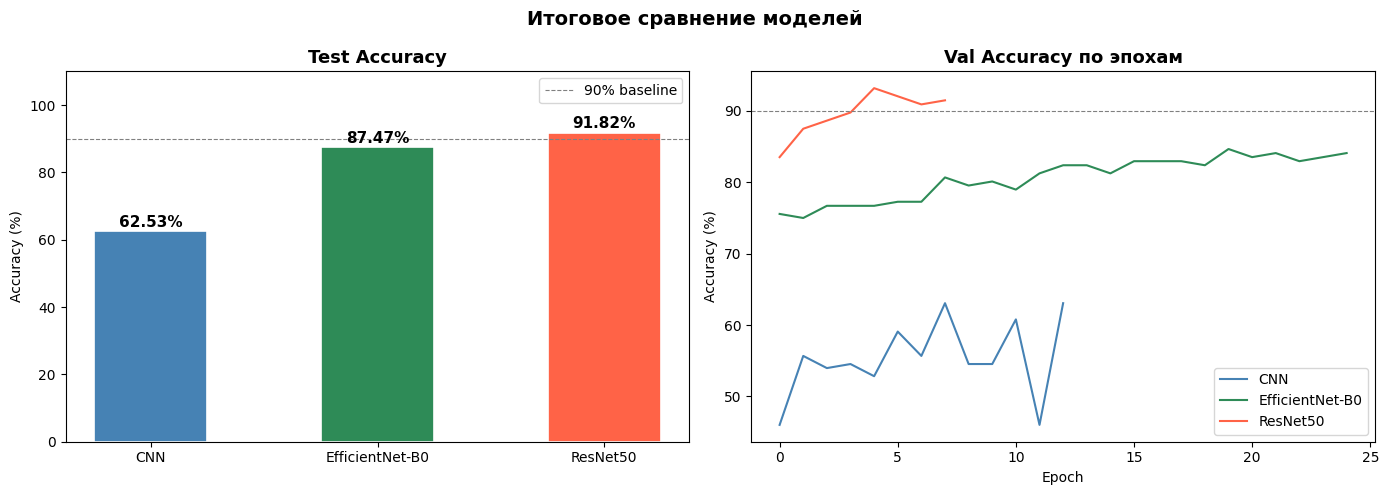

In [ ]:
model_names = ['CNN', 'EfficientNet-B0', 'ResNet50']
test_accs = [cnn_test_acc, eff_test_acc, res_test_acc]

best_vals = [max(cnn_history['val_acc']), max(eff_history['val_acc']), max(res_history['val_acc'])]

epochs_ran  = [len(cnn_history['train_loss']), len(eff_history['train_loss']), len(res_history['train_loss'])]

num_params  = [sum(p.numel() for p in cnn_model.parameters()), sum(p.numel() for p in eff_model.parameters()), sum(p.numel() for p in res_model.parameters())]

print('\n' + '='*65)
print(f'  {"Модель":<20} {"Test Acc":>10} {"Best Val":>10} {"Эпох":>7} {"Параметров":>14}')
print('='*65)
for i in range(3):
    print(f'  {model_names[i]:<20} {test_accs[i]:>9.2f}% {best_vals[i]:>9.2f}% {epochs_ran[i]:>7} {num_params[i]:>14,}')
print('='*65)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['steelblue', 'seagreen', 'tomato']

bars = axes[0].bar(model_names, test_accs, color=colors, width=0.5, edgecolor='white', linewidth=1.2)
for bar, acc in zip(bars, test_accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
                 f'{acc:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[0].set_ylim(0, 110)
axes[0].set_title('Test Accuracy', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].axhline(90, color='gray', linestyle='--', linewidth=0.8, label='90% baseline')
axes[0].legend()

axes[1].plot(cnn_history['val_acc'], color='steelblue', label='CNN')
axes[1].plot(eff_history['val_acc'], color='seagreen',  label='EfficientNet-B0')
axes[1].plot(res_history['val_acc'], color='tomato',    label='ResNet50')
axes[1].set_title('Val Accuracy по эпохам', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].axhline(90, color='gray', linestyle='--', linewidth=0.8)

plt.suptitle('Итоговое сравнение моделей', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()